# 5. Linear programming  [CO 12.1, 13.1, 14.3.1]

In [13]:
import numpy as np
import matplotlib.pyplot as plt
from ipywidgets import interact, FloatSlider, IntSlider, Dropdown, fixed

np.set_printoptions(precision=4, suppress=True)
import itertools
import networkx as nx
from scipy.optimize import linprog

def check(label, ok):
    print(f"{'✓' if ok else '✗'}  {label}")

---
## 5.1 An LP you can see

**Task.** Solve

$$\max_x\ 3x_1 + 2x_2 \quad\text{s.t.}\quad x_1 + x_2\le4,\ \ x_1 + 3x_2\le6,\ \ x_1\le3,\ \ x\ge0$$

with `scipy.optimize.linprog`. Plot the feasible polygon, the level lines of the objective, its gradient $c$ and the optimal vertex. Mark all vertices with their objective value.

### Prediction

- The optimum is at the vertex $(3, 1)$ with value 11. That vertex is special: **three** constraint lines pass through it ($x_1 = 3$, $x_1 + x_2 = 4$, $x_1 + 3x_2 = 6$), a degenerate vertex.

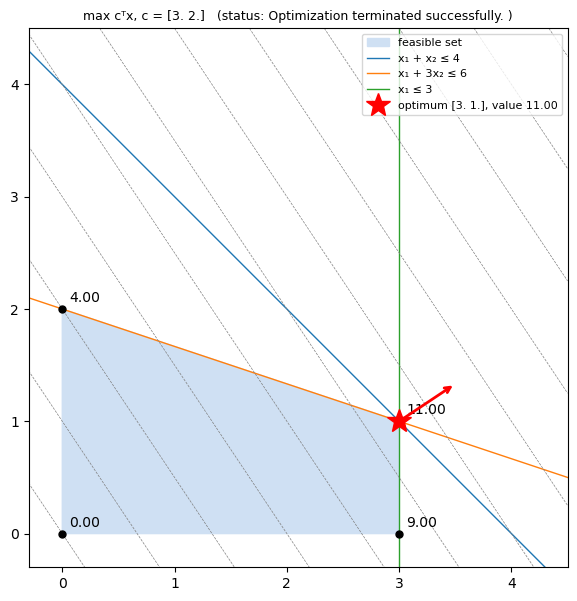

In [14]:
A = np.array([[1.0, 1.0], [1.0, 3.0], [1.0, 0.0]]); b = np.array([4.0, 6.0, 3.0]); c = np.array([3.0, 2.0])
names = ["x₁ + x₂ ≤ 4", "x₁ + 3x₂ ≤ 6", "x₁ ≤ 3"]

def vertices(A, b):
    # all intersections of two constraint lines (incl. x ≥ 0) that satisfy every constraint
    G = np.vstack([A, -np.eye(2)]); h = np.r_[b, 0, 0]
    V = []
    for i, j in itertools.combinations(range(len(G)), 2):
        M = G[[i, j]]
        if abs(np.linalg.det(M)) < 1e-12: continue
        v = np.linalg.solve(M, h[[i, j]])
        if np.all(G @ v <= h + 1e-9) and not any(np.allclose(v, w) for w in V):
            V.append(v)
    V = np.array(V); ctr = V.mean(0)
    return V[np.argsort(np.arctan2(V[:, 1] - ctr[1], V[:, 0] - ctr[0]))]

def plot_lp(A, b, c, names=names, ax=None, lim=(-0.3, 4.5)):
    ax = ax or plt.gca()
    res = linprog(-c, A_ub=A, b_ub=b, bounds=[(0, None)] * 2, method="highs")
    V = vertices(A, b)
    ax.fill(*V.T, color="#cfe0f3", label="feasible set")
    xx = np.linspace(*lim, 2)
    for (a1, a2), bi, nm in zip(A, b, names):
        if abs(a2) > 1e-12: ax.plot(xx, (bi - a1 * xx) / a2, lw=1, label=nm)
        else: ax.axvline(bi / a1, lw=1, label=nm, color="C2")
    G1, G2 = np.meshgrid(np.linspace(*lim, 200), np.linspace(*lim, 200))
    cs = ax.contour(G1, G2, c[0] * G1 + c[1] * G2, levels=12, colors="gray", linewidths=0.5, linestyles="--")
    for v in V:
        ax.plot(*v, "ko", ms=5); ax.annotate(f"{c @ v:.2f}", v, textcoords="offset points", xytext=(5, 5))
    if res.status == 0:
        ax.plot(*res.x, "r*", ms=18, label=f"optimum {res.x.round(3)}, value {-res.fun:.2f}")
        ax.annotate("", xy=res.x + 0.6 * c / np.linalg.norm(c), xytext=res.x, arrowprops=dict(arrowstyle="->", color="r", lw=2))
    ax.set_xlim(*lim); ax.set_ylim(*lim); ax.set_aspect("equal"); ax.legend(fontsize=8, loc="upper right")
    ax.set_title(f"max cᵀx, c = {c.round(2)}   (status: {res.message.split('(')[0]})", fontsize=9)
    return res

plt.figure(figsize=(7, 7)); res = plot_lp(A, b, c); plt.show()

### Verify numerically

In [15]:
V = vertices(A, b)
print("vertices:\n", V, "\nobjective at vertices:", V @ c)
active = np.isclose(A @ res.x, b)
print("active constraints at the optimum:", [n for n, a in zip(names, active) if a])
check("linprog optimum (3, 1) with value 11", np.allclose(res.x, [3, 1]) and np.isclose(-res.fun, 11))
check("the optimum equals the best vertex", np.isclose(-res.fun, (V @ c).max()))
check("all three constraints are active at (3, 1) (degenerate vertex)", active.all())

vertices:
 [[-0. -0.]
 [ 3. -0.]
 [ 3.  1.]
 [ 0.  2.]] 
objective at vertices: [ 0.  9. 11.  4.]
active constraints at the optimum: ['x₁ + x₂ ≤ 4', 'x₁ + 3x₂ ≤ 6', 'x₁ ≤ 3']
✓  linprog optimum (3, 1) with value 11
✓  the optimum equals the best vertex
✓  all three constraints are active at (3, 1) (degenerate vertex)


### Explore: rotate $c$; make $c$ parallel to an edge; unbounded and infeasible LPs

Note: with $x\ge0$, **each** of the three constraints bounds $x_1$ on its own ($x_1\le4$, $x_1\le6$, $x_1\le3$), so removing any one or two of them still leaves a bounded polygon. To make this LP unbounded you have to remove all three (only $x\ge0$ left).

In [16]:
@interact(phi=FloatSlider(min=0, max=360, step=1, value=33.7))
def rotate_c(phi):
    cc = np.array([np.cos(np.deg2rad(phi)), np.sin(np.deg2rad(phi))])
    plt.figure(figsize=(7, 7)); plot_lp(A, b, cc); plt.show()

interactive(children=(FloatSlider(value=33.7, description='phi', max=360.0, step=1.0), Output()), _dom_classes…

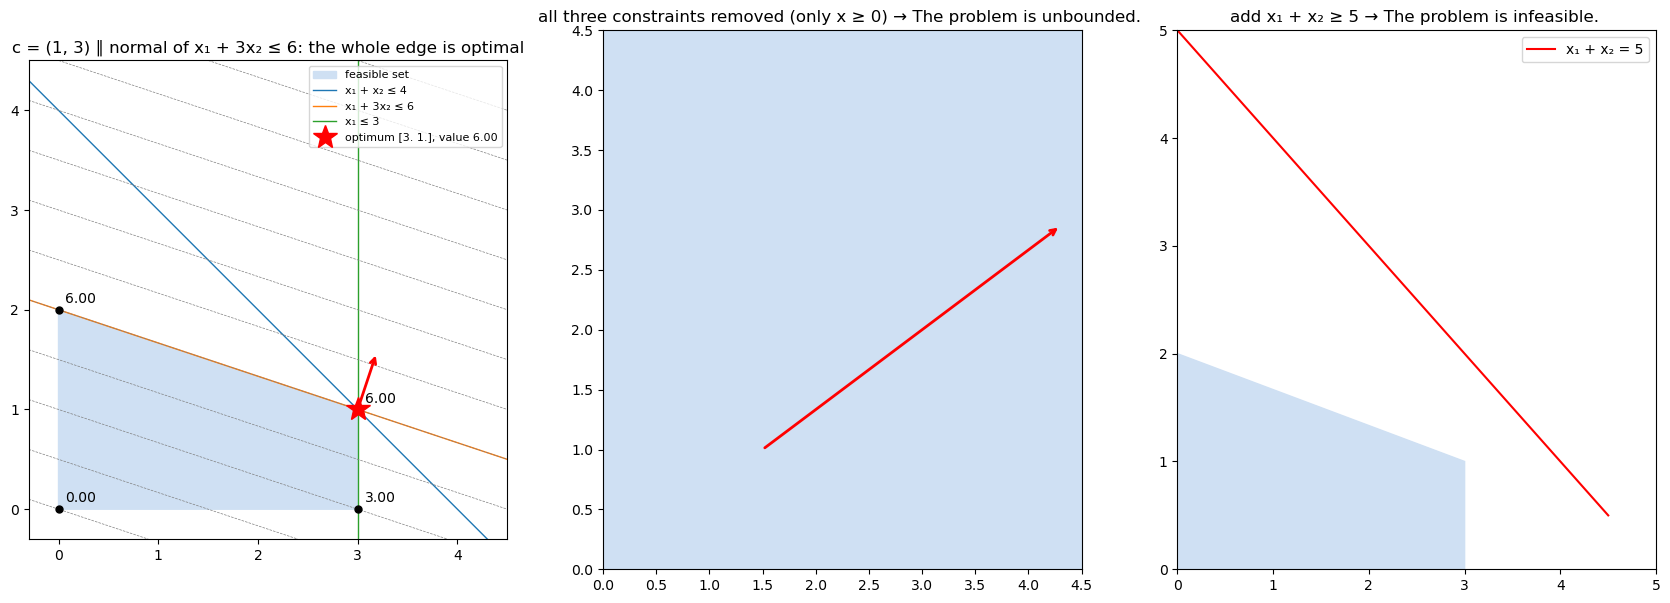

✓  c ∥ edge: every point of the edge (0,2)–(3,1) has the same optimal value 6
✓  removing any single constraint still leaves a bounded LP (status 0)
✓  removing all three → linprog reports unbounded (status 3)
✓  adding x₁ + x₂ ≥ 5 → linprog reports infeasible (status 2)


In [17]:
fig, axes = plt.subplots(1, 3, figsize=(21, 7))
plot_lp(A, b, np.array([1.0, 3.0]), ax=axes[0])                          # parallel to the edge x₁ + 3x₂ = 6
axes[0].set_title("c = (1, 3) ∥ normal of x₁ + 3x₂ ≤ 6: the whole edge is optimal")
r_unb = linprog(-c, bounds=[(0, None)] * 2, method="highs")
axes[1].set_title(f"all three constraints removed (only x ≥ 0) → {r_unb.message.split('(')[0]}")
xx = np.linspace(0, 4.5, 2); axes[1].fill_between(xx, 0, 4.5, color="#cfe0f3")
axes[1].annotate("", xy=(4.3, 4.3 * 2 / 3), xytext=(1.5, 1.0), arrowprops=dict(arrowstyle="->", color="r", lw=2))
axes[1].set_xlim(0, 4.5); axes[1].set_ylim(0, 4.5)
r_inf = linprog(-c, A_ub=np.vstack([A, [-1, -1]]), b_ub=np.r_[b, -5], bounds=[(0, None)] * 2, method="highs")
axes[2].set_title(f"add x₁ + x₂ ≥ 5 → {r_inf.message.split('(')[0]}")
V0 = vertices(A, b); axes[2].fill(*V0.T, color="#cfe0f3"); axes[2].plot(xx, 5 - xx, "r", label="x₁ + x₂ = 5")
axes[2].legend(); axes[2].set_xlim(0, 5); axes[2].set_ylim(0, 5)
plt.show()
r_edge = linprog(-np.array([1.0, 3.0]), A_ub=A, b_ub=b, bounds=[(0, None)] * 2, method="highs")
edge_pts = [np.array([0, 2]), np.array([3, 1]), np.array([1.5, 1.5])]
check("c ∥ edge: every point of the edge (0,2)–(3,1) has the same optimal value 6",
      np.allclose([np.array([1, 3]) @ p for p in edge_pts], -r_edge.fun))
single = [linprog(-c, A_ub=np.delete(A, i, 0), b_ub=np.delete(b, i), bounds=[(0, None)] * 2, method="highs").status for i in range(3)]
check("removing any single constraint still leaves a bounded LP (status 0)", single == [0, 0, 0])
check("removing all three → linprog reports unbounded (status 3)", r_unb.status == 3)
check("adding x₁ + x₂ ≥ 5 → linprog reports infeasible (status 2)", r_inf.status == 2)

---
### Explain

**1. Why is the optimum always at a vertex (or along an edge)?**

The level sets of $c^\top x$ are parallel lines and the objective increases in the direction of $c$. Sliding the line in direction $c$, the last point(s) of the polygon it touches are the optimum. A linear function on a segment is maximised at an endpoint (it is monotone along the segment), so on a polygon, which is the convex hull of its vertices, $c^\top x = \sum\theta_ic^\top v_i\le\max_ic^\top v_i$: some vertex is always at least as good as any feasible point (checked: linprog's value equals the best vertex value). The last contact is either a single vertex or a whole edge.

**2. When is it not unique?**

When $c$ is perpendicular to an edge at the optimum, i.e. $c$ is parallel to that edge's outward normal: the level lines are parallel to the edge, so the whole edge is optimal. Example: $c = (1, 3)$ is parallel to the normal of $x_1 + 3x_2\le6$, and every point of the edge from $(0,2)$ to $(3,1)$ gives value 6. With the slider this happens at isolated angles (the boundaries between "this vertex wins" and "the next vertex wins"). In higher dimensions a whole face can be optimal.

**3. Which constraints are active at the optimum?**

All three: $x_1 = 3$, $x_1 + x_2 = 4$ and $x_1 + 3x_2 = 6$ all hold with equality at $(3, 1)$ (only $x\ge0$ is inactive). In 2-D a vertex needs only two active constraints, so $(3,1)$ is a **degenerate** vertex: one constraint is redundant there ($x_1+x_2\le4$ is implied by the other two near that point). Degeneracy has a visible consequence in 5.2: the dual variables at this vertex are **not unique**.

---
## 5.2 Weak and strong duality for LPs

**Task.** Write the LP above in standard form (slack variables, [CO 12.1]) and derive its dual (by hand, then using [CO 14.3.1]). Solve primal and dual with `linprog`; also read the dual variables in `res.ineqlin.marginals`. For random feasible $x$ and $y$, plot $c^\top x$ and $b^\top y$.

**Standard form.** With slacks $s\ge0$ and the max turned into a min:
$$\min_{\tilde x}\ \tilde c^\top\tilde x \quad\text{s.t.}\quad \tilde A\tilde x = b,\ \tilde x\ge0,\qquad \tilde x = (x_1, x_2, s_1, s_2, s_3),\ \ \tilde c = (-3, -2, 0, 0, 0),\ \ \tilde A = [A\ \ I].$$

**Dual** [CO 14.3.1]: $\max_y\ b^\top y$ s.t. $\tilde A^\top y\le\tilde c$. (The notes write "$Ay\ge c$"; the transpose and the inequality direction are as here.) Here $\tilde A^\top y\le\tilde c$ reads $A^\top y\le(-3,-2)$ and $y\le0$. Substituting $w = -y\ge0$ gives the familiar pair

$$\text{(P)}\ \max\ c^\top x\ \text{ s.t. } Ax\le b,\ x\ge0 \qquad\Longleftrightarrow\qquad \text{(D)}\ \min\ b^\top w\ \text{ s.t. } A^\top w\ge c,\ w\ge0.$$

Weak duality in this form reads $c^\top x\le b^\top w$ for feasible $x, w$ (it is $\tilde c^\top\tilde x\ge b^\top y$ in the standard min form).

### Prediction

- Both optimal values are 11. Because the optimal vertex is degenerate, the dual optimum is a whole segment of $w$'s, so the "price" of a constraint depends on whether its right-hand side goes up or down.

In [18]:
A_t = np.hstack([A, np.eye(3)]); c_t = np.r_[-c, 0, 0, 0]
prim_std = linprog(c_t, A_eq=A_t, b_eq=b, bounds=[(0, None)] * 5, method="highs")
dual_std = linprog(-b, A_ub=A_t.T, b_ub=c_t, bounds=[(None, None)] * 3, method="highs")      # max bᵀy ⇔ min −bᵀy
prim = linprog(-c, A_ub=A, b_ub=b, bounds=[(0, None)] * 2, method="highs")
dual = linprog(b, A_ub=-A.T, b_ub=-c, bounds=[(0, None)] * 3, method="highs")             # min bᵀw, Aᵀw ≥ c
print("standard-form primal x̃* =", prim_std.x, "  value c̃ᵀx̃ =", prim_std.fun)
print("standard-form dual   y* =", dual_std.x, "  value bᵀy  =", -dual_std.fun)
print("max-form primal x* =", prim.x, " value", -prim.fun)
print("min-form dual   w* =", dual.x, " value", dual.fun)
print("res.ineqlin.marginals of the primal (∂ objective of min −cᵀx / ∂b):", prim.ineqlin.marginals)

standard-form primal x̃* = [3. 1. 0. 0. 0.]   value c̃ᵀx̃ = -11.0
standard-form dual   y* = [-2. -0. -1.]   value bᵀy  = -11.0
max-form primal x* = [3. 1.]  value 11.0
min-form dual   w* = [2. 0. 1.]  value 11.0
res.ineqlin.marginals of the primal (∂ objective of min −cᵀx / ∂b): [-0.     -0.6667 -2.3333]


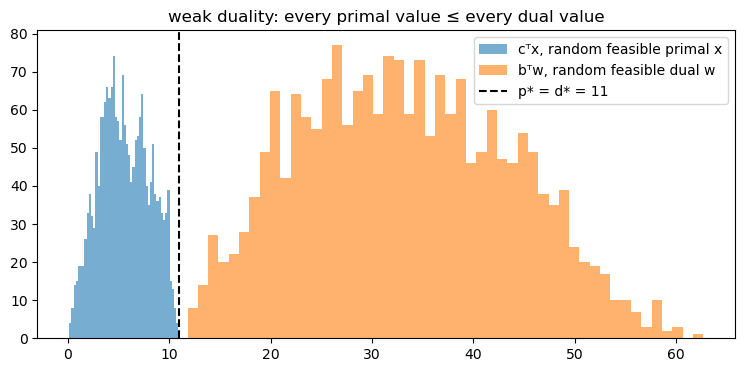

In [19]:
# random feasible primal points (inside the polygon) and random feasible dual points w ≥ 0 with Aᵀw ≥ c
rng = np.random.default_rng(0)
Xs = rng.uniform(0, 4, (20000, 2)); Xs = Xs[np.all(Xs @ A.T <= b, axis=1)][:2000]
Ws = rng.uniform(0, 5, (200000, 3)); Ws = Ws[np.all(Ws @ A >= c, axis=1)][:2000]
plt.figure(figsize=(9, 4))
plt.hist(Xs @ c, bins=50, alpha=0.6, label="cᵀx, random feasible primal x")
plt.hist(Ws @ b, bins=50, alpha=0.6, label="bᵀw, random feasible dual w")
plt.axvline(11, color="k", ls="--", label="p* = d* = 11")
plt.legend(); plt.title("weak duality: every primal value ≤ every dual value"); plt.show()

### Verify numerically: weak and strong duality, and sensitivity

In [20]:
check("weak duality: max cᵀx over random feasible x ≤ min bᵀw over random feasible w", (Xs @ c).max() <= (Ws @ b).min())
check("strong duality: p* = d* = 11 (both forms)", np.isclose(-prim.fun, dual.fun) and np.isclose(prim_std.fun, -dual_std.fun))
check("standard form: c̃ᵀx̃* = bᵀy*  and  y* = −w*-type (y ≤ 0)", np.all(dual_std.x <= 1e-12))
check("marginals of linprog = −(a dual optimal w)", np.allclose(A.T @ -prim.ineqlin.marginals >= c - 1e-9, True)
      and np.isclose(b @ -prim.ineqlin.marginals, 11))
w_star = -prim.ineqlin.marginals
check("complementary slackness: wᵢ*(bᵢ − aᵢᵀx*) = 0 and x*ⱼ((Aᵀw*)ⱼ − cⱼ) = 0",
      np.allclose(w_star * (b - A @ prim.x), 0) and np.allclose(prim.x * (A.T @ w_star - c), 0))

# sensitivity: re-solve with bᵢ ± 1
print("\n constraint        w* (linprog)   Δp* if bᵢ+1   Δp* if bᵢ−1    min / max of wᵢ over the dual optimal set")
for i in range(3):
    up = -linprog(-c, A_ub=A, b_ub=b + np.eye(3)[i], bounds=[(0, None)] * 2, method="highs").fun - 11
    dn = 11 + linprog(-c, A_ub=A, b_ub=b - np.eye(3)[i], bounds=[(0, None)] * 2, method="highs").fun
    lo = linprog(np.eye(3)[i], A_ub=-A.T, b_ub=-c, A_eq=b[None], b_eq=[11], bounds=[(0, None)] * 3, method="highs").fun
    hi = -linprog(-np.eye(3)[i], A_ub=-A.T, b_ub=-c, A_eq=b[None], b_eq=[11], bounds=[(0, None)] * 3, method="highs").fun
    print(f" {names[i]:<14}   {w_star[i]:8.3f}      {up:8.3f}       {dn:8.3f}           [{lo:.3f}, {hi:.3f}]")

✓  weak duality: max cᵀx over random feasible x ≤ min bᵀw over random feasible w
✓  strong duality: p* = d* = 11 (both forms)
✓  standard form: c̃ᵀx̃* = bᵀy*  and  y* = −w*-type (y ≤ 0)
✓  marginals of linprog = −(a dual optimal w)
✓  complementary slackness: wᵢ*(bᵢ − aᵢᵀx*) = 0 and x*ⱼ((Aᵀw*)ⱼ − cⱼ) = 0

 constraint        w* (linprog)   Δp* if bᵢ+1   Δp* if bᵢ−1    min / max of wᵢ over the dual optimal set
 x₁ + x₂ ≤ 4         0.000         0.000          2.000           [0.000, 2.000]
 x₁ + 3x₂ ≤ 6        0.667         0.000          0.667           [0.000, 0.667]
 x₁ ≤ 3              2.333         1.000          2.333           [1.000, 2.333]


---
### Explain

**1. Check $c^\top x\ge b^\top y$ for every feasible pair (weak duality) and equality at the optimum (strong duality).**

In the standard min form $\tilde c^\top\tilde x\ge b^\top y$ for every feasible pair: $y^\top\tilde A\le\tilde c^\top$ and $\tilde x\ge0$ give $\tilde c^\top\tilde x\ge y^\top\tilde A\tilde x = y^\top b$. In the max/min pair this is $c^\top x\le b^\top w$, and the two histograms never overlap: the best random primal value is below 11 and the best random dual value is above 11. At the optimum both equal 11 (strong duality, which always holds for feasible bounded LPs). Complementary slackness also checks out: the constraint $x_1+x_2\le4$ with $w_1>0$ or $=0$, etc.

**2. Interpret each dual variable as the change in the optimum when the right-hand side of its constraint is increased by one (check it by re-solving).**

$w_i^\star = \partial p^\star/\partial b_i$: the **shadow price** of resource $i$, how much the optimal value improves per extra unit of right-hand side. Re-solving with $b_i+1$ gives $\Delta p^\star = 0, 0, +1$ for the three constraints: increasing $x_1\le3$ to $x_1\le4$ moves the optimum to $(4,0)$ with value 12, while loosening either of the other two does nothing (the point $(3,1)$ stays optimal, held by $x_1\le3$ and the other constraint).

**Subtlety: this vertex is degenerate**, so the dual optimum is not unique. It is the segment between $w = (2, 0, 1)$ and $w = (0, \frac23, \frac73)$ (all give $b^\top w = 11$). The table shows the range of each $w_i$ over that set. The *increase* in $p^\star$ when $b_i$ goes up equals the **smallest** $w_i$ in the set; the *decrease* when $b_i$ goes down equals the **largest** (e.g. tightening $x_1+x_2\le4$ to $\le3$ costs 2 units, tightening $x_1 + 3x_2\le6$ costs $2/3$, tightening $x_1\le3$ costs $7/3$). linprog returns just one point of the set (printed); its values match the one-sided derivatives only in the direction it happens to represent. With a non-degenerate optimum the dual is unique and both one-sided derivatives coincide.

---
## 5.3 Max flow and min cut

**Task.** Reproduce the example graph of [CO 13.1]: nodes $s, 1, 2, t$, edges $(s,1), (s,2), (1,2), (1,t), (2,t)$ with capacities $c = (4, 2, 2, 3, 5)$. Solve the max-flow LP with `linprog`, draw the graph labelling each edge with $f_{uv}/c_{uv}$, and enumerate the four cuts $S_1,\dots,S_4$ with their capacities. Compare with `networkx.maximum_flow` and `minimum_cut`.

LP: $\max\ f_{s1} + f_{s2}$ s.t. flow conservation at nodes 1 and 2 ($A_{eq}f = 0$), $0\le f\le c$.

### Prediction

- Cut capacities: $S_1 = \{s\}$: $4 + 2 = 6$; $S_2 = \{s,1\}$: $2 + 2 + 3 = 7$; $S_3 = \{s, 2\}$: $4 + 5 = 9$; $S_4 = \{s,1,2\}$: $3+5 = 8$. So max flow = min cut = 6, achieved by saturating both edges leaving $s$.

flows (s1, s2, 12, 1t, 2t): [4. 2. 1. 3. 3.]   max flow = 6.0


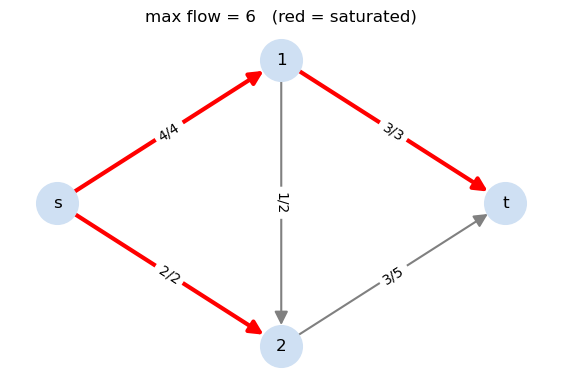

S1 = ['s']:  capacity = 6
S2 = ['1', 's']:  capacity = 7
S3 = ['2', 's']:  capacity = 9
S4 = ['1', '2', 's']:  capacity = 8

networkx: max flow = 6.0, min cut = 6.0, S = ['s']


In [21]:
edges = [("s", "1"), ("s", "2"), ("1", "2"), ("1", "t"), ("2", "t")]
cap = np.array([4.0, 2.0, 2.0, 3.0, 5.0])
inner = ["1", "2"]

def maxflow_lp(edges, cap, inner, source="s"):
    A_eq = np.array([[(e[1] == v) - (e[0] == v) for e in edges] for v in inner], float)   # inflow − outflow = 0
    obj = -np.array([float(e[0] == source) for e in edges])
    return linprog(obj, A_eq=A_eq, b_eq=np.zeros(len(inner)), bounds=list(zip(np.zeros(len(cap)), cap)), method="highs")

def cut_capacity(S, edges, cap):
    return sum(c for (u, v), c in zip(edges, cap) if u in S and v not in S)

def draw_flow(edges, cap, flow, title, ax=None, pos=None):
    G = nx.DiGraph(); G.add_edges_from(edges)
    pos = pos or {"s": (0, 0), "1": (1, 1), "2": (1, -1), "t": (2, 0)}
    ax = ax or plt.gca()
    sat = [np.isclose(f, c) for f, c in zip(flow, cap)]
    nx.draw_networkx(G, pos, ax=ax, node_color="#cfe0f3", node_size=900, arrowsize=20,
                     edge_color=["red" if s else "gray" for s in sat], width=[3 if s else 1.5 for s in sat])
    nx.draw_networkx_edge_labels(G, pos, {e: f"{f:.0f}/{c:.0f}" for e, f, c in zip(edges, flow, cap)}, ax=ax)
    ax.set_title(title); ax.axis("off")

res = maxflow_lp(edges, cap, inner)
print("flows (s1, s2, 12, 1t, 2t):", res.x, "  max flow =", -res.fun)
plt.figure(figsize=(7, 4.5)); draw_flow(edges, cap, res.x, f"max flow = {-res.fun:.0f}   (red = saturated)"); plt.show()

cuts = [{"s"}, {"s", "1"}, {"s", "2"}, {"s", "1", "2"}]
for k, S in enumerate(cuts, 1):
    print(f"S{k} = {sorted(S)}:  capacity = {cut_capacity(S, edges, cap):.0f}")

G = nx.DiGraph()
for (u, v), c_ in zip(edges, cap): G.add_edge(u, v, capacity=c_)
nx_val, nx_flow = nx.maximum_flow(G, "s", "t"); cut_val, (S_side, T_side) = nx.minimum_cut(G, "s", "t")
print(f"\nnetworkx: max flow = {nx_val}, min cut = {cut_val}, S = {sorted(S_side)}")

### Verify numerically, and read the dual variables

In [22]:
caps = [cut_capacity(S, edges, cap) for S in cuts]
check("cut capacities are (6, 7, 9, 8)", caps == [6, 7, 9, 8])
check("max flow (LP) = min cut = 6 = networkx", np.isclose(-res.fun, min(caps)) and np.isclose(nx_val, 6) and np.isclose(cut_val, 6))
check("flow conservation at nodes 1 and 2", np.allclose([res.x[0] - res.x[2] - res.x[3], res.x[1] + res.x[2] - res.x[4]], 0))
print("dual variables of the capacity bounds f ≤ c (res.upper.marginals):", res.upper.marginals)
print("dual variables of conservation (res.eqlin.marginals, node potentials):", res.eqlin.marginals)
cut_edges = [e for e, m_ in zip(edges, res.upper.marginals) if abs(m_) > 1e-9]
print("edges with a nonzero capacity multiplier:", cut_edges)
check("nonzero capacity multipliers = the edges crossing the minimum cut S₁ = {s}",
      set(cut_edges) == {(u, v) for (u, v) in edges if u in cuts[0] and v not in cuts[0]})

✓  cut capacities are (6, 7, 9, 8)
✓  max flow (LP) = min cut = 6 = networkx
✓  flow conservation at nodes 1 and 2
dual variables of the capacity bounds f ≤ c (res.upper.marginals): [-1. -1.  0.  0.  0.]
dual variables of conservation (res.eqlin.marginals, node potentials): [-0. -0.]
edges with a nonzero capacity multiplier: [('s', '1'), ('s', '2')]
✓  nonzero capacity multipliers = the edges crossing the minimum cut S₁ = {s}


### Explore: capacities with sliders, and a larger random graph

In [23]:
@interact(c_s1=FloatSlider(min=0, max=8, value=4), c_s2=FloatSlider(min=0, max=8, value=2), c_12=FloatSlider(min=0, max=8, value=2),
          c_1t=FloatSlider(min=0, max=8, value=3), c_2t=FloatSlider(min=0, max=8, value=5))
def explore_caps(c_s1, c_s2, c_12, c_1t, c_2t):
    cp = np.array([c_s1, c_s2, c_12, c_1t, c_2t])
    r = maxflow_lp(edges, cp, inner)
    caps_ = [cut_capacity(S, edges, cp) for S in cuts]
    best = int(np.argmin(caps_))
    plt.figure(figsize=(7, 4.5))
    draw_flow(edges, cp, r.x, f"max flow = {-r.fun:.2f};  cuts = {np.round(caps_, 2)};  min cut S{best + 1} = {sorted(cuts[best])}")
    plt.show()

interactive(children=(FloatSlider(value=4.0, description='c_s1', max=8.0), FloatSlider(value=2.0, description=…

✓  random graph (10 nodes, 21 edges): LP max flow 6 = networkx 6 = min cut 6


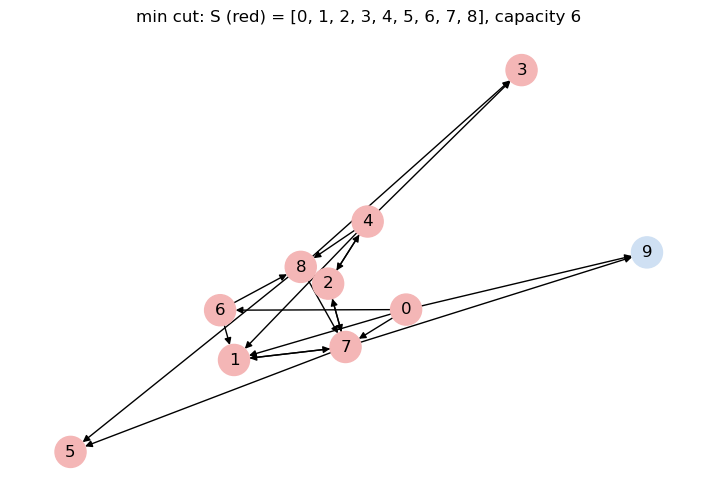

In [24]:
rng = np.random.default_rng(3)
n_nodes = 10
Gr = nx.gnp_random_graph(n_nodes, 0.35, seed=3, directed=True)
Gr = nx.DiGraph([(u, v) for u, v in Gr.edges() if u != n_nodes - 1 and v != 0])      # no edges into s=0 or out of t=9
for u, v in Gr.edges(): Gr[u][v]["capacity"] = float(rng.integers(1, 10))
E = list(Gr.edges()); C = np.array([Gr[u][v]["capacity"] for u, v in E])
A_eq = np.array([[(e[1] == v) - (e[0] == v) for e in E] for v in range(1, n_nodes - 1)], float)
r = linprog(-np.array([float(e[0] == 0) for e in E]), A_eq=A_eq, b_eq=np.zeros(n_nodes - 2), bounds=list(zip(np.zeros(len(C)), C)), method="highs")
val_nx, _ = nx.maximum_flow(Gr, 0, n_nodes - 1); cut_nx, (Sr, Tr) = nx.minimum_cut(Gr, 0, n_nodes - 1)
check(f"random graph ({n_nodes} nodes, {len(E)} edges): LP max flow {-r.fun:.0f} = networkx {val_nx:.0f} = min cut {cut_nx:.0f}",
      np.isclose(-r.fun, val_nx) and np.isclose(val_nx, cut_nx))
plt.figure(figsize=(9, 6))
pos = nx.spring_layout(Gr, seed=1)
nx.draw_networkx(Gr, pos, node_color=["#f4b6b6" if v in Sr else "#cfe0f3" for v in Gr.nodes()], node_size=500)
plt.title(f"min cut: S (red) = {sorted(Sr)}, capacity {cut_nx:.0f}"); plt.axis("off"); plt.show()

---
### Explain

**1. Check that max flow = min cut. Which edges are saturated?**

Max flow (LP) = 6 = capacity of the minimum cut $S_1 = \{s\}$ = networkx's value (the other cuts have 7, 9, 8; the notes give 4 for $S_2$, but the edge $(1,t)$ with capacity 3 also crosses it, so it is 7). The edges leaving the source, $(s,1)$ with 4/4 and $(s,2)$ with 2/2, are saturated; they are exactly the edges crossing the minimum cut, so no more flow can leave $s$. Other edges may or may not be saturated depending on which of the many optimal flows the solver returns (e.g. $(1,t)$ carries 3/3 in one optimal flow); only the cut edges *must* be saturated in every maximum flow.

**2. Look at the dual variables of the max-flow LP: which of them are nonzero and how do they identify the minimum cut?**

The multipliers of the capacity bounds $f_{uv}\le c_{uv}$ (`res.upper.marginals`) are nonzero only on $(s,1)$ and $(s,2)$: the edges of the minimum cut. Each has value $-1$ (in linprog's minimisation sign convention): raising the capacity of a cut edge by one unit raises the max flow by one, while raising any other capacity changes nothing. The multipliers of the conservation constraints are node "potentials" $z_v$: they are 0 on the source side and 1 on the sink side (up to sign and the solver's convention), which is exactly the indicator $z$ of the cut in the min-cut LP of [CO 13.1.2]. So the dual solution *is* the cut: $d_{uv} = 1$ on edges going from the $s$-side to the $t$-side, 0 elsewhere.

**3. Why is this an instance of strong duality?**

As shown in [CO 13.1.2], the min-cut LP (relaxed from 0/1 to continuous variables) is the **Lagrange dual** of the max-flow LP. Weak duality gives the easy direction: any flow is at most any cut capacity (everything that leaves $s$ must cross the cut). Strong duality, which always holds for feasible bounded LPs, says the best flow *equals* the best cut. Moreover the dual LP has an integral optimal solution (its constraint matrix is totally unimodular), so the LP optimum is attained at a real 0/1 cut. Hence max flow = min cut (the Ford–Fulkerson theorem), confirmed on the example, under the sliders, and on the random 10-node graph.